NEU-DET Dataset and Image Processing Foundations

This notebook inspects the steel-surface defect dataset and establishes the image-processing basis for later ML and CNN models.

Setup

The dataset contains grayscale steel-surface images and annotation files for six defect classes.

In [2]:
from pathlib import Path
import xml.etree.ElementTree as ET
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
ROOT = PROJECT / 'dataset' / 'NEU-DET'
OUTPUTS = PROJECT / 'outputs' / 'neu_dataset_exploration'
OUTPUTS.mkdir(parents=True, exist_ok=True)
CLASSES = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Dataset Inventory

This section counts images, records dimensions and channels, and checks the available annotations.

In [3]:
rows = []
for split in ['train', 'validation']:
    for category in CLASSES:
        files = sorted((ROOT / split / 'images' / category).glob('*'))
        shapes, modes = set(), set()
        for file in files:
            image = cv2.imread(str(file), cv2.IMREAD_UNCHANGED)
            shapes.add(str(image.shape))
            modes.add('grayscale' if image.ndim == 2 else f'{image.shape[2]} channels')
        rows.append({'split': split, 'category': category, 'image_count': len(files), 'dimensions': sorted(shapes), 'channels': sorted(modes), 'format': sorted({file.suffix.lower() for file in files})})
inventory = pd.DataFrame(rows)
display(inventory)
inventory.to_csv(OUTPUTS / 'dataset_inventory.csv', index=False)

,split,category,image_count,dimensions,channels,format
0,train,crazing,240,"[(200, 200, 3)]",[3 channels],[.jpg]
1,train,inclusion,240,"[(200, 200, 3)]",[3 channels],[.jpg]
2,train,patches,240,"[(200, 200, 3)]",[3 channels],[.jpg]
3,train,pitted_surface,240,"[(200, 200, 3)]",[3 channels],[.jpg]
4,train,rolled-in_scale,240,"[(200, 200, 3)]",[3 channels],[.jpg]
5,train,scratches,240,"[(200, 200, 3)]",[3 channels],[.jpg]
6,validation,crazing,60,"[(200, 200, 3)]",[3 channels],[.jpg]
7,validation,inclusion,60,"[(200, 200, 3)]",[3 channels],[.jpg]
8,validation,patches,60,"[(200, 200, 3)]",[3 channels],[.jpg]
9,validation,pitted_surface,60,"[(200, 200, 3)]",[3 channels],[.jpg]


Annotation Correspondence

Every image is checked against its Pascal VOC XML annotation file and bounding boxes are counted.

In [4]:
rows = []
for split in ['train', 'validation']:
    for category in CLASSES:
        images = sorted((ROOT / split / 'images' / category).glob('*'))
        annotations = ROOT / split / 'annotations'
        matched = 0
        boxes = 0
        missing = []
        for image in images:
            xml = annotations / f'{image.stem}.xml'
            if not xml.exists():
                missing.append(image.name)
                continue
            matched += 1
            boxes += len(ET.parse(xml).findall('.//object'))
        rows.append({'split': split, 'category': category, 'images': len(images), 'matched_annotations': matched, 'bounding_boxes': boxes, 'missing_annotations': missing})
annotation_summary = pd.DataFrame(rows)
display(annotation_summary)
annotation_summary.to_csv(OUTPUTS / 'annotation_correspondence.csv', index=False)

,split,category,images,matched_annotations,bounding_boxes,missing_annotations
0,train,crazing,240,239,529,[crazing_240.jpg]
1,train,inclusion,240,240,737,[]
2,train,patches,240,240,689,[]
3,train,pitted_surface,240,240,384,[]
4,train,rolled-in_scale,240,240,496,[]
5,train,scratches,240,240,497,[]
6,validation,crazing,60,60,162,[]
7,validation,inclusion,60,60,147,[]
8,validation,patches,60,60,184,[]
9,validation,pitted_surface,60,60,105,[]


Sample Images and Bounding Boxes

Samples show the visual appearance of each class and how the annotation boxes locate defect regions.

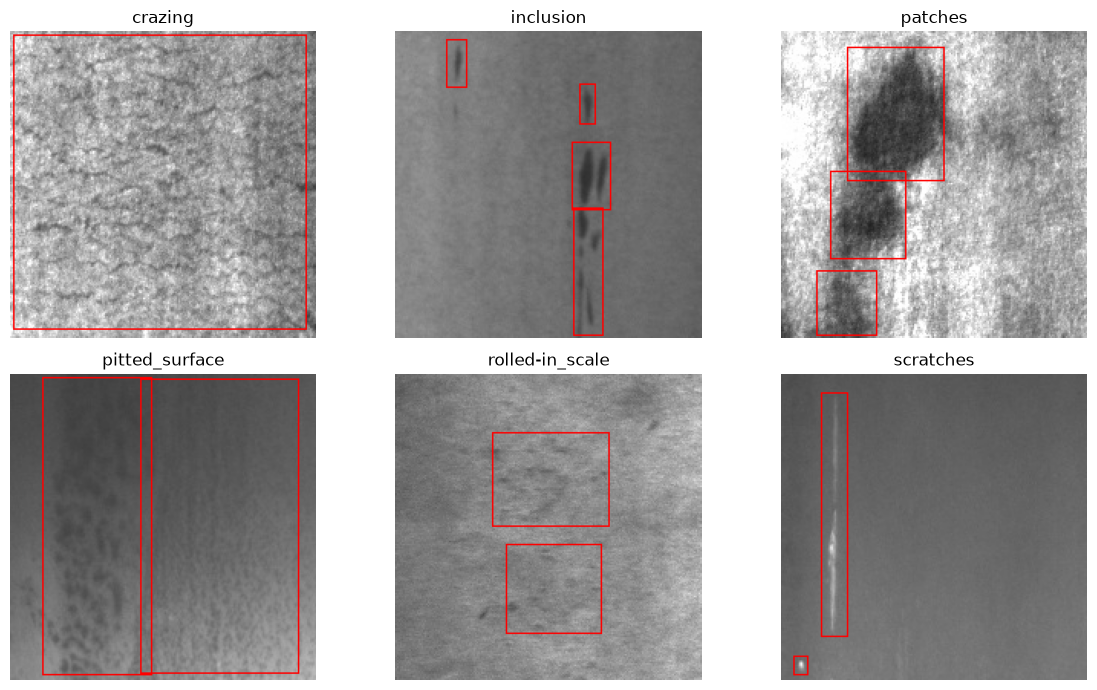

In [5]:
def draw_boxes(file, split):
    image = cv2.cvtColor(cv2.imread(str(file)), cv2.COLOR_BGR2RGB)
    xml = ROOT / split / 'annotations' / f'{file.stem}.xml'
    if xml.exists():
        root = ET.parse(xml).getroot()
        for box in root.findall('.//bndbox'):
            x0, y0 = int(box.findtext('xmin')), int(box.findtext('ymin'))
            x1, y1 = int(box.findtext('xmax')), int(box.findtext('ymax'))
            cv2.rectangle(image, (x0, y0), (x1, y1), (255, 0, 0), 1)
    return image

items = [(category, sorted((ROOT / 'train' / 'images' / category).glob('*'))[0]) for category in CLASSES]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, (category, file) in zip(axes.ravel(), items):
    axis.imshow(draw_boxes(file, 'train'))
    axis.set_title(category)
    axis.axis('off')
plt.tight_layout()
plt.savefig(OUTPUTS / 'sample_images_with_boxes.png', bbox_inches='tight')
plt.show()

Intensity Statistics

Grayscale intensity summaries show whether the classes differ in brightness and contrast.

mean    std  minimum  maximum
split      category                                        
train      crazing          135.60  28.59    35.28   245.58
           inclusion        101.84  11.92    67.28   138.25
           patches          131.91  53.91     9.85   245.24
           pitted_surface   178.81  26.58   101.53   234.98
           rolled-in_scale  126.43  16.97    56.38   202.04
           scratches         97.98  21.85    60.11   228.04
validation crazing          163.12  30.92    41.25   253.42
           inclusion        124.47  17.44    78.40   171.53
           patches          134.90  55.45     8.83   242.40
           pitted_surface   168.08  27.06    91.77   227.43
           rolled-in_scale   83.83  12.56    34.90   146.02
           scratches         83.82  21.13    51.20   234.23

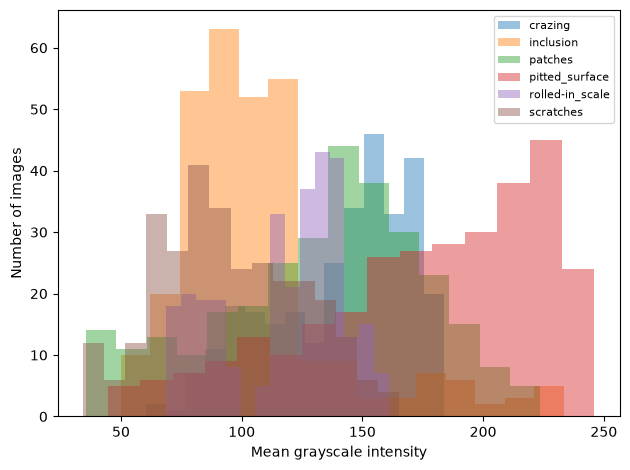

In [6]:
rows = []
for split in ['train', 'validation']:
    for category in CLASSES:
        for file in sorted((ROOT / split / 'images' / category).glob('*')):
            image = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
            rows.append({'split': split, 'category': category, 'file': file.name, 'mean': image.mean(), 'std': image.std(), 'minimum': int(image.min()), 'maximum': int(image.max())})
statistics = pd.DataFrame(rows)
display(statistics.groupby(['split', 'category']).mean(numeric_only=True).round(2))
statistics.to_csv(OUTPUTS / 'intensity_statistics.csv', index=False)
for category in CLASSES:
    plt.hist(statistics.loc[statistics.category == category, 'mean'], bins=15, alpha=.45, label=category)
plt.xlabel('Mean grayscale intensity')
plt.ylabel('Number of images')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUTS / 'intensity_distribution.png', bbox_inches='tight')
plt.show()

Morphology Demonstration

Morphology is applied to a thresholded response to remove isolated noise and connect nearby defect pixels.

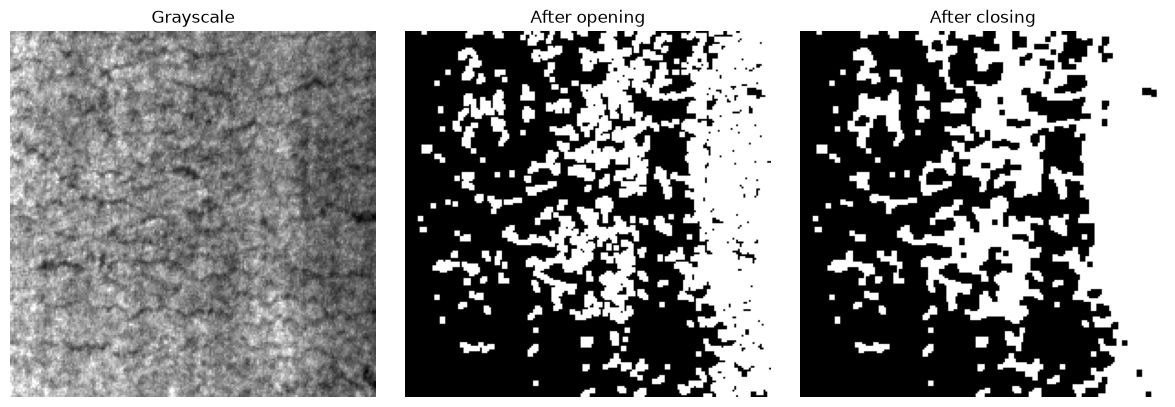

In [7]:
file = items[0][1]
gray = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)  # The kernel defines the neighborhood used by morphology.
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)  # Opening removes small isolated regions.
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)  # Closing fills small gaps and holes.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axis, image, title in zip(axes, [gray, opened, closed], ['Grayscale', 'After opening', 'After closing']):
    axis.imshow(image, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.savefig(OUTPUTS / 'morphology_demo.png', bbox_inches='tight')
plt.show()

DCT Demonstration

The DCT separates broad surface structure from fine texture that may help distinguish defect classes.

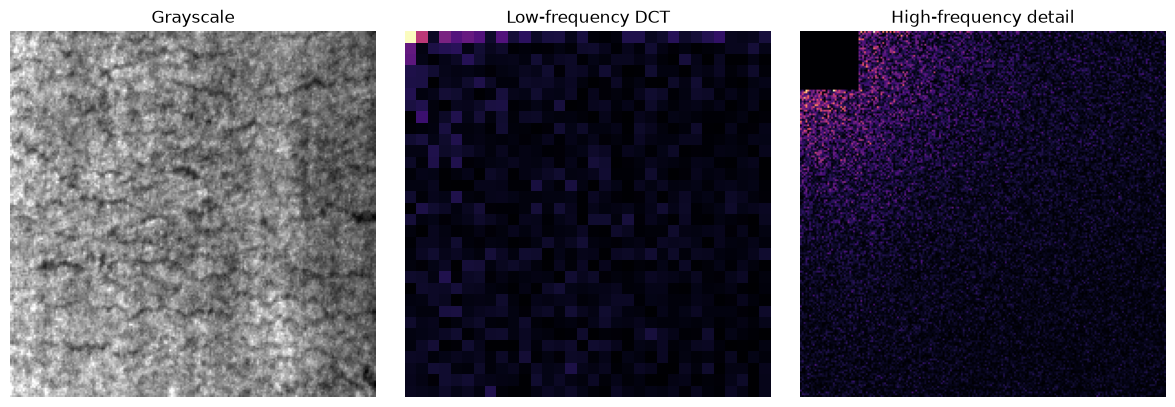

In [8]:
dct = cv2.dct(gray.astype(np.float32) / 255)  # DCT converts spatial pixels into frequency coefficients.
low = dct[:32, :32]  # The top-left coefficients represent low-frequency structure.
high = dct.copy()
high[:32, :32] = 0  # Removing low frequencies leaves higher-frequency detail.
low_display = cv2.normalize(np.log1p(np.abs(low)), None, 0, 1, cv2.NORM_MINMAX)
high_display = cv2.normalize(np.log1p(np.abs(high)), None, 0, 1, cv2.NORM_MINMAX)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(gray, cmap='gray'); axes[0].set_title('Grayscale'); axes[0].axis('off')
axes[1].imshow(low_display, cmap='magma'); axes[1].set_title('Low-frequency DCT'); axes[1].axis('off')
axes[2].imshow(high_display, cmap='magma'); axes[2].set_title('High-frequency detail'); axes[2].axis('off')
plt.tight_layout()
plt.savefig(OUTPUTS / 'dct_demo.png', bbox_inches='tight')
plt.show()

Initial Findings

These observations determine which image analytics will be passed to the ML and CNN notebooks.

In [9]:
print('NEU-DET provides fixed-size grayscale images, so grayscale analytics are the primary representation.')
print('Bounding-box annotations support localization evaluation and object-detection experiments.')
print('Morphology is a refinement step for thresholded responses, not the main classifier.')
print('DCT energy is a candidate feature for fine texture, scratches, and repetitive surface patterns.')
print('Notebook 02 will extract intensity, edge, texture, DCT, and morphology-based features.')

NEU-DET provides fixed-size grayscale images, so grayscale analytics are the primary representation.
Bounding-box annotations support localization evaluation and object-detection experiments.
Morphology is a refinement step for thresholded responses, not the main classifier.
DCT energy is a candidate feature for fine texture, scratches, and repetitive surface patterns.
Notebook 02 will extract intensity, edge, texture, DCT, and morphology-based features.
